# Analytical Konya density-elasticity comparison

This notebook evaluates analytical local density elasticities of the **reconstructed** Konya 1972 and Konya 1983 burden equations. It uses the centralized Gole Gohar reference scenario and the existing explosive-density and rock-density grids.

**Decision gate:** `RESEARCH_COMPARATOR_ONLY`

These are deterministic equation responses. The sampled grid does not establish a geological probability distribution, explosive-product feasibility, predictive accuracy, or an operational design range.


In [1]:
from pathlib import Path
import importlib.util
import json
import sys

import numpy as np
from IPython.display import Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (
        path for path in candidates
        if (path / "pyproject.toml").is_file()
        and (path / "src" / "blastdesign").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the BlastDesign-AI project.")

script_path = PROJECT_ROOT / "scripts" / "generate_konya_density_elasticity_artifacts.py"
spec = importlib.util.spec_from_file_location("konya_elasticity_artifacts", script_path)
artifact_generator = importlib.util.module_from_spec(spec)
spec.loader.exec_module(artifact_generator)

print("Python executable:", sys.executable)
print("Project root:", PROJECT_ROOT)


Python executable: C:\Users\A.Mehregan\miniconda3\envs\mining-ai\python.exe
Project root: C:\Users\A.Mehregan\Projects\BlastDesign-AI


## Method

Let \(q=\rho_e/\rho_r\), where both densities use g/cm³ and the density definitions intended by the source equations. Hole diameter \(d\) uses metres in the reconstructed formulas:

\[
B_{1972}=37.8\,d\,q^{0.33}, \qquad
B_{1983}=12\,d\,(2q+1.5).
\]

The exponent is **0.33**, matching the implementation. It is not replaced with \(1/3\).

For an input \(x\), the dimensionless local elasticity is

\[
E_x=\frac{x}{B}\frac{\partial B}{\partial x},
\]

holding the other inputs fixed. Therefore,

\[
E_{\rho_e}^{1972}=0.33,\qquad E_{\rho_r}^{1972}=-0.33,
\]
\[
E_{\rho_e}^{1983}=\frac{2q}{2q+1.5}
=\frac{q}{q+0.75},\qquad
E_{\rho_r}^{1983}=-E_{\rho_e}^{1983}.
\]

The default calculation holds diameter at the centralized reference value, 251 mm. It evaluates 7 explosive densities and 12 rock densities, giving 84 pairs and 168 rows for the two equations. The reference pair is 0.85 and 4.37 g/cm³.

The local percentage interpretation is \(\mathrm{d}B/B=E_x\,\mathrm{d}x/x\). Finite changes generally require evaluating the burden equation at the changed inputs.


In [2]:
reference, elasticity_grid, artifact_paths = artifact_generator.generate_artifacts(PROJECT_ROOT)

print("Reference table:", reference.shape)
print("Grid table:", elasticity_grid.shape)
print("Density pairs:", elasticity_grid.attrs["scenario_count"])
print("Decision gate:", elasticity_grid.attrs["decision_gate"])
print(
    "Reference density ratio:",
    f"{reference['explosive_to_rock_density_ratio'].iloc[0]:.6f}",
)
display(reference[[
    "model_id", "burden_m", "explosive_density_elasticity",
    "rock_density_elasticity",
]].round(6))

limits = elasticity_grid.groupby("model_id")[
    ["explosive_density_elasticity", "rock_density_elasticity"]
].agg(["min", "max"])
display(limits.round(6))


Reference table: (2, 9)
Grid table: (168, 9)
Density pairs: 84
Decision gate: RESEARCH_COMPARATOR_ONLY
Reference density ratio: 0.194508


,model_id,burden_m,explosive_density_elasticity,rock_density_elasticity
0,CONV_KONYA_1972,5.527324,0.330000,-0.330000
1,CONV_KONYA_1983,5.689716,0.205936,-0.205936


explosive_density_elasticity            \
                                         min       max   
model_id                                                 
CONV_KONYA_1972                     0.330000  0.330000   
CONV_KONYA_1983                     0.149733  0.425532   

                rock_density_elasticity            
                                    min       max  
model_id                                           
CONV_KONYA_1972               -0.330000 -0.330000  
CONV_KONYA_1983               -0.425532 -0.149733

In [3]:
konya_1983 = elasticity_grid.loc[
    elasticity_grid["model_id"].eq("CONV_KONYA_1983")
]
for label, value in (
    ("Minimum", konya_1983["explosive_density_elasticity"].min()),
    ("Maximum", konya_1983["explosive_density_elasticity"].max()),
):
    matches = konya_1983.loc[
        np.isclose(
            konya_1983["explosive_density_elasticity"],
            value, rtol=1e-12, atol=1e-12,
        ),
        ["explosive_density_g_cm3", "rock_density_g_cm3"],
    ]
    print(f"{label} sampled Konya 1983 explosive-density elasticity: {value:.6f}")
    display(matches)


Minimum sampled Konya 1983 explosive-density elasticity: 0.149733


,explosive_density_g_cm3,rock_density_g_cm3
23,0.7,5.3


Maximum sampled Konya 1983 explosive-density elasticity: 0.425532


,explosive_density_g_cm3,rock_density_g_cm3
145,1.0,1.8


## Comparison figure

The left panel shows the exact analytical elasticity curves over the sampled ratio interval. Dots mark Konya 1983 values from the Cartesian grid. The star and dashed line identify the reference pair.

The right panel colors the sampled Konya 1983 explosive-density elasticities. White dots identify sample locations; colored cells are a display of those samples, not an interpolated geological response surface. Irregular spacing follows the existing rock-density grid.

For both equations, the corresponding rock-density elasticity has the same magnitude and opposite sign.


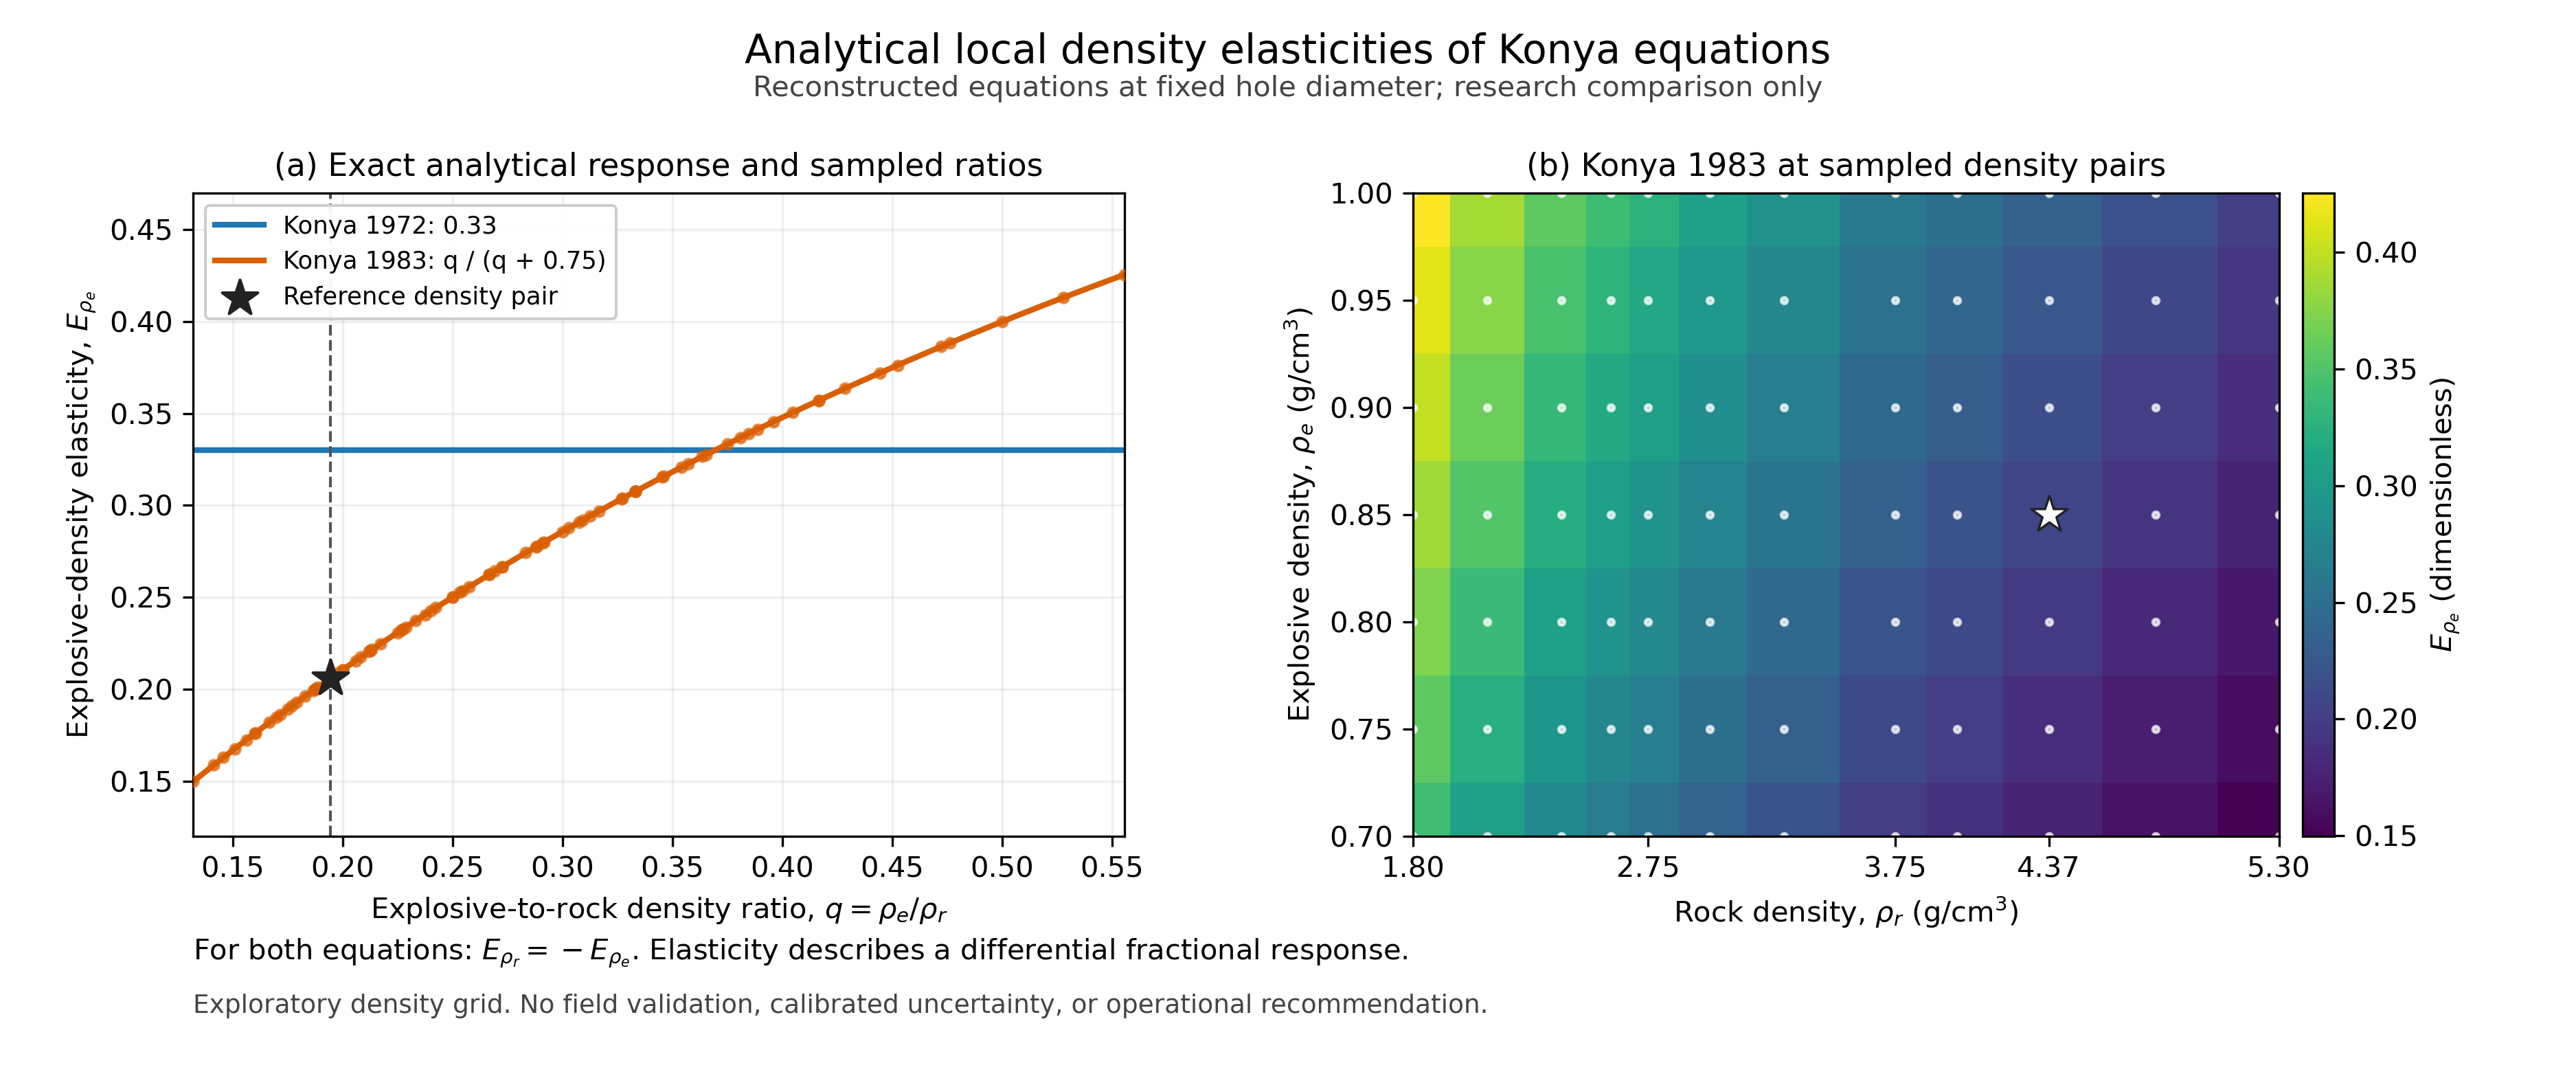

Exported decision gate: RESEARCH_COMPARATOR_ONLY
Saved: data\processed\konya_density_elasticity_reference.csv
Saved: data\processed\konya_density_elasticity_grid.csv
Saved: data\processed\konya_density_elasticity_metadata.json
Saved: outputs\figures\konya_density_elasticity_comparison.png


In [4]:
display(Image(filename=str(artifact_paths["figure"]), width=1100))

with artifact_paths["metadata"].open(encoding="utf-8") as stream:
    exported_metadata = json.load(stream)

print("Exported decision gate:", exported_metadata["decision_gate"])
for path in artifact_paths.values():
    print("Saved:", path.relative_to(PROJECT_ROOT))


## Interpretation

- Konya 1972 has constant density elasticities of +0.33 and −0.33 throughout the grid.
- At the reference pair, Konya 1983 has explosive-density elasticity approximately **+0.205936**, with rock-density elasticity **−0.205936**.
- The sampled Konya 1983 explosive-density elasticity spans approximately **0.149733 to 0.425532**. Its analytical elasticity increases with \(q\), so it increases with explosive density at fixed rock density and decreases with rock density at fixed explosive density.
- Opposite signs arise from dependence on the same density ratio. They do not establish two separately validated physical mechanisms.
- A larger elasticity means a stronger **local fractional response of that equation**. It does not establish greater predictive importance, field sensitivity, model accuracy, or calibrated uncertainty.

Mineral, grain, dry-bulk, saturated-bulk, and in-situ densities are not interchangeable. The exploratory density pairs require their own geological and explosive-product applicability assessment before any physical interpretation.

The outputs retain `RESEARCH_COMPARATOR_ONLY` and provide no operational burden recommendation.


## Reproduction and saved outputs

From an activated project environment, this command regenerates the same data and figure:

```text
python scripts\generate_konya_density_elasticity_artifacts.py
```

Saved outputs:

- `data/processed/konya_density_elasticity_reference.csv`
- `data/processed/konya_density_elasticity_grid.csv`
- `data/processed/konya_density_elasticity_metadata.json`
- `outputs/figures/konya_density_elasticity_comparison.png`

CSV numbers retain their computational precision. Displayed summaries use six decimal places for readability. The JSON file preserves units, reference inputs, sampled intervals, and interpretation warnings because CSV does not preserve DataFrame attributes.

The three saved-data regression checks can be run with:

```text
python -m pytest tests\test_density_elasticity_artifacts.py -q
```

The figure uses Matplotlib at 300 dpi. Rendering can vary between Matplotlib versions; the regression checks compare numerical data and metadata rather than image bytes.
